# Masaya volcanic SO2: complete measured UV traverses
## Problem
Recover the SO2 slant-column profile across both measured car traverses of Masaya volcano on14January2018. The selected method is Esse etal.(2020) intensity-space spectral fitting, specifically its published no-flat-field condition. Every one of the360 spectra is actively fitted here. The unknown is an integrated gas column, not a volumetric plume or an emission rate; wind/geometry needed for flux are not available.

There is no independent measured column truth. Frozen original-code estimates are method references only. Historical paper values, independently reproduced upstream values and fresh cleaned-code measurements are identified separately.

In [1]:
from pathlib import Path
import sys,time,json,os
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data,preprocess
from src.physics_model import forward,optical_depth,instrument_lineshape
from src.solvers import reconstruct,fit_spectrum,doas_comparison,INITIAL
from src.visualization import summary_figure
data=load_data(ROOT/'data/raw_data.npz')
print({k:v.shape for k,v in data.items()})
print('Full acquired spectra:',data['spectra'].shape,'Time span(s):',data['elapsed_seconds'][[0,-1]])

{'wavelength': (2048,), 'spectra': (360, 2048), 'dark': (2048,), 'model_wavelength': (1201,), 'solar': (1201,), 'cross_sections': (3, 1201), 'elapsed_seconds': (360,)}
Full acquired spectra: (360, 2048) Time span(s): [   0. 1798.]


## Data
The actual Ocean Optics Flame-S FLMS02101 observations are supplied from the paper's CC BY4.0 archive. Headers specify100ms integration and10 coadds. The zenith-viewing telescope was driven along a road approximately3km west of the crater. All360 spectra00316–00675 are retained in their published order and original float64 precision.

The measured dark and external solar/SO2/O3/Ring spectra are legitimate calibration. External spectra were cubic-interpolated to the1201-point padded grid without using target observations. No flat-field measurement is bundled. The paper explicitly tested this omission on these traverses, reporting increased residual standard deviation from0.46% to0.60%; those are historical reports, not this run's measurements.

## Physics
The high-resolution intensity is $F(\lambda)B(\lambda)\exp[-a\sigma_s(\lambda)-b\sigma_o(\lambda)-r\sigma_r(\lambda)]$. Here F is solar intensity, B a cubic broadband response, a the SO2 column, b the ozone column, r the Ring amplitude and the sigmas their supplied cross sections. A single normalized asymmetric super-Gaussian convolution models the spectrometer; shift/stretch registration precedes cubic sampling at measured wavelengths.

SO2 and O3 columns have molecules/cm² units, cross sections cm²/molecule, wavelength nm. Convolving the total transmitted intensity preserves solar and saturation interactions that a weak-absorption optical-depth approximation misses. Rowwise dark/stray subtraction preserves the original arithmetic; this matters because the fit is ill-conditioned.

## Method
Each spectrum is independently fit by the original Levenberg–Marquardt intensity objective. Thirteen parameters include SO2/O3/Ring, four broadband coefficients, two registration coefficients and four ILS coefficients. Initialization follows the paper table; no target-dependent warm starts or parameter clipping. The entire320nm-bounded selected path runs below.

The native code sometimes warns that covariance cannot be estimated. We retain these warnings and do not turn infinite covariance into invented uncertainty bars. The fit and column themselves must be finite. A separate DOAS-style comparison uses a measured20-spectrum reference and I0-corrected cross sections; it is explicitly a fixed-registration diagnostic, not a claim to reproduce the paper's external QDOAS software.

In [2]:
started=time.perf_counter()
columns,details=reconstruct(data)
elapsed=time.perf_counter()-started
with np.load(ROOT/'notebooks/reference_outputs/upstream.npz',allow_pickle=False) as z:
    original=z['parameters'][:,0].copy()
    original_fit=z['fit'].copy()
diff=columns-original
print('Full fresh360-spectrum runtime(s):',elapsed)
print('SO2 range(molecules/cm²):',columns.min(),columns.max())
print('Original comparison: max difference',np.max(abs(diff)),'dynamic-range NRMSE',np.sqrt(np.mean(diff**2))/np.ptp(original))
print('Finite fit spectra:',np.isfinite(details['fit']).all())
print('Finite native parameter uncertainty fraction:',np.isfinite(details['parameter_errors']).mean())

D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch10_20261027\astro_earth_physics\tasks\masaya_uv_so2_column_transects\src\solvers.py:10: OptimizeWarning: Covariance of the parameters could not be estimated
  p,cov=curve_fit(f,wavelength,intensity,INITIAL if initial is None else initial)


Full fresh360-spectrum runtime(s): 92.01026060001459
SO2 range(molecules/cm²): -1.8090997817616796e+16 1.742372338403191e+18
Original comparison: max difference 0.0 dynamic-range NRMSE 0.0
Finite fit spectra: True
Finite native parameter uncertainty fraction: 0.6111111111111112


## Results
The first group preserves the paper's profile and representative spectral-fit logic, extended to the complete measured wavelength/time matrix and residual field. Original and fresh profiles are independently computed. All residuals come from the fresh fit, not an archived plotted spectrum.

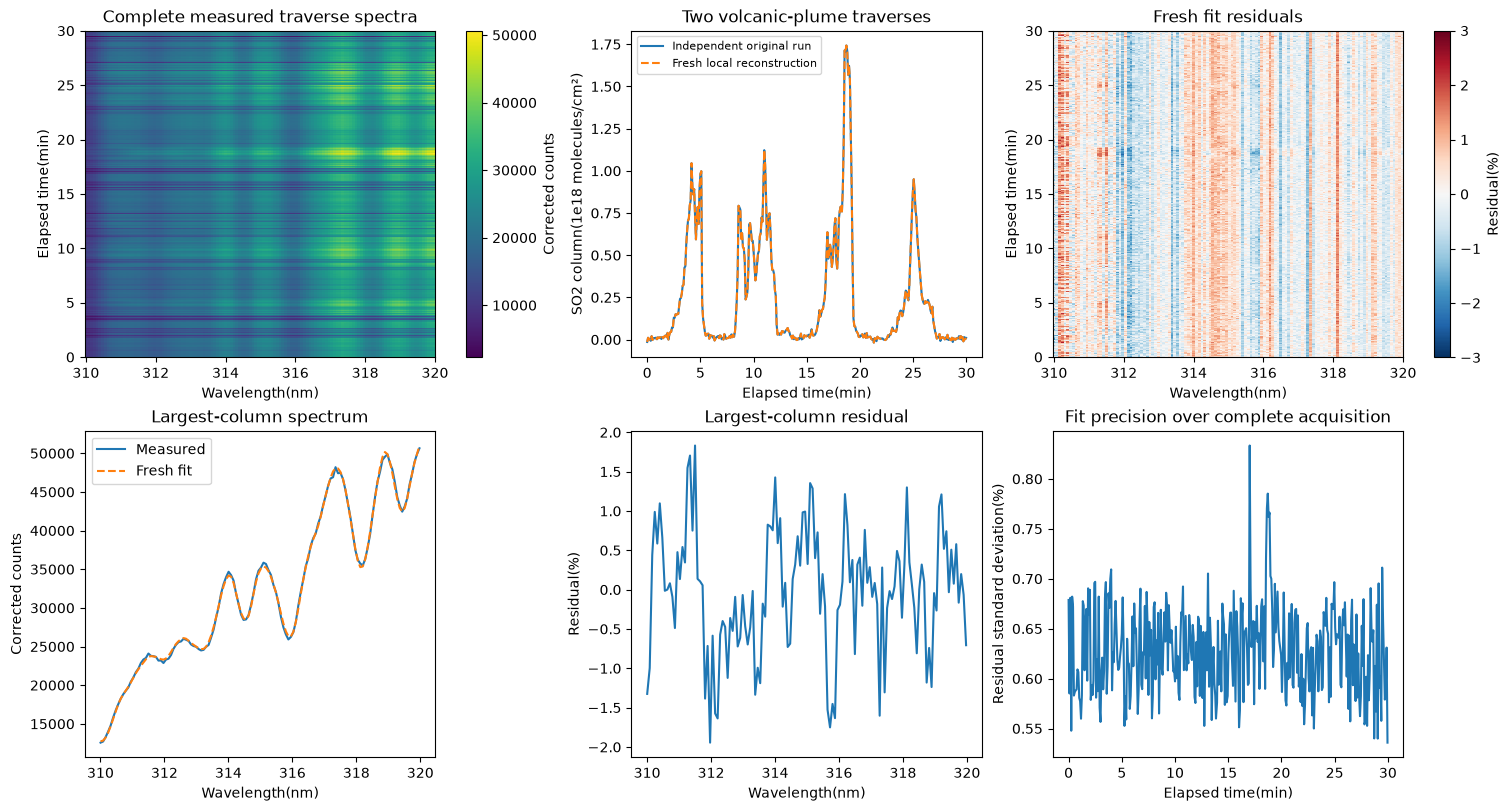

Fresh mean residual standard deviation(%): 0.6283061179639226
Reproduced original mean residual standard deviation(%): 0.6283061179639226
Historical paper no-flat average:0.60%; not a fixture for this run.


In [3]:
fig=summary_figure(data,details,original)
plt.show()
residual=(details['corrected']-details['fit'])/details['corrected']
print('Fresh mean residual standard deviation(%):',100*np.mean(np.std(residual,axis=1)))
print('Reproduced original mean residual standard deviation(%):',100*np.mean(np.std((details['corrected']-original_fit)/details['corrected'],axis=1)))
print('Historical paper no-flat average:0.60%; not a fixture for this run.')

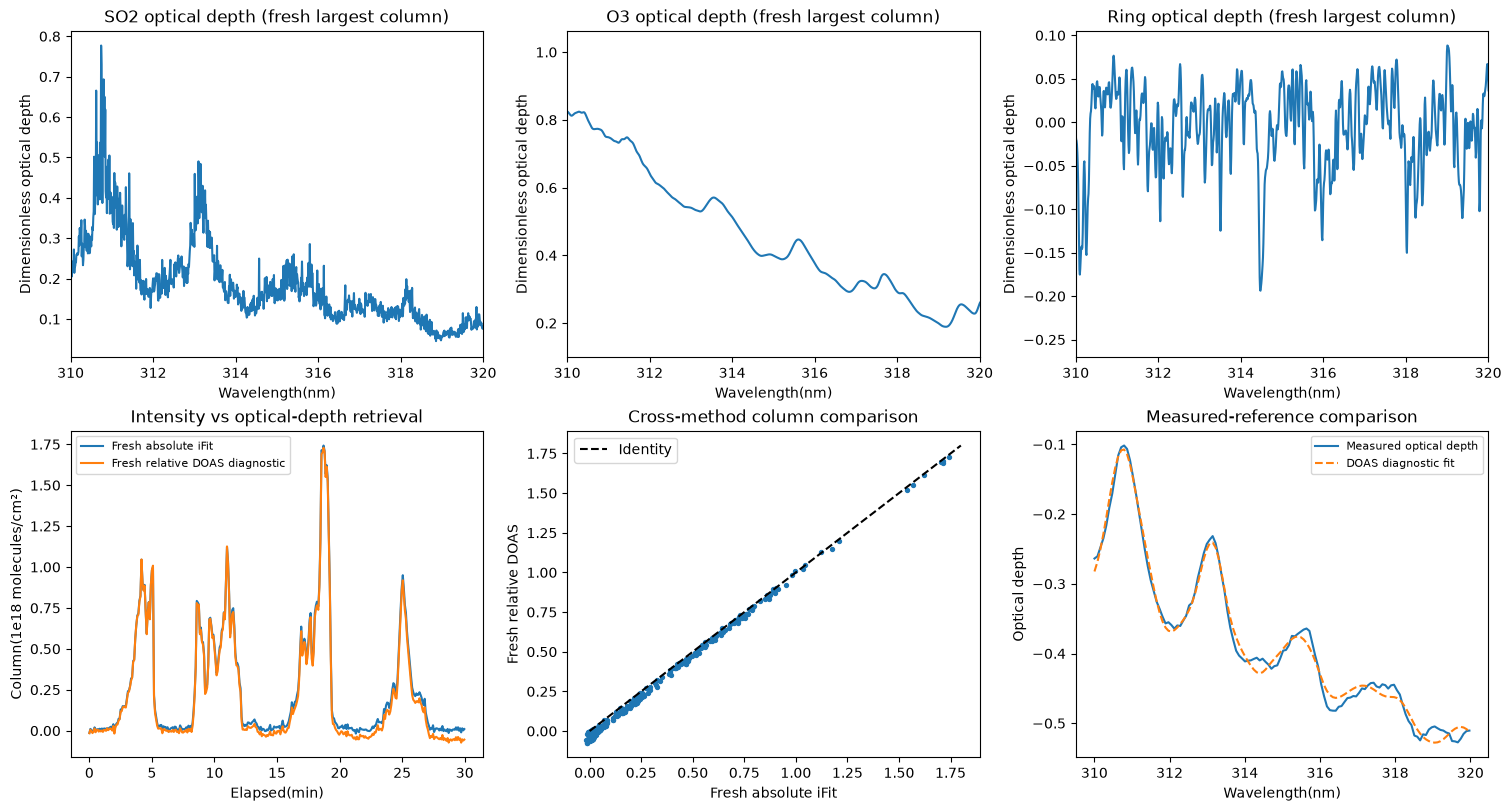

DOAS diagnostic correlation: 0.9990728923240646
DOAS is relative to first20 measurements; ILS/registration use fresh mean fitted nuisance parameters. It is not an independent instrument calibration or QDOAS parity claim.


In [4]:
doas,measured_od,fitted_od=doas_comparison(data,details)
idx=int(np.argmax(columns));p=details['parameters'][idx];t=data['elapsed_seconds']/60
od=optical_depth(p,data['cross_sections'])
fig2,axes=plt.subplots(2,3,figsize=(15,8),layout='constrained')
for j,label in enumerate(['SO2','O3','Ring']):
    axes[0,j].plot(data['model_wavelength'],od[j]);axes[0,j].set(title=label+' optical depth (fresh largest column)',xlabel='Wavelength(nm)',ylabel='Dimensionless optical depth',xlim=(310,320))
axes[1,0].plot(t,columns/1e18,label='Fresh absolute iFit');axes[1,0].plot(t,doas/1e18,label='Fresh relative DOAS diagnostic');axes[1,0].set(title='Intensity vs optical-depth retrieval',xlabel='Elapsed(min)',ylabel='Column(1e18 molecules/cm²)');axes[1,0].legend(fontsize=8)
axes[1,1].scatter(columns/1e18,doas/1e18,s=8);axes[1,1].plot([0,1.8],[0,1.8],'k--',label='Identity');axes[1,1].set(title='Cross-method column comparison',xlabel='Fresh absolute iFit',ylabel='Fresh relative DOAS');axes[1,1].legend()
axes[1,2].plot(details['wavelength'],measured_od[idx],label='Measured optical depth');axes[1,2].plot(details['wavelength'],fitted_od[idx],'--',label='DOAS diagnostic fit');axes[1,2].set(title='Measured-reference comparison',xlabel='Wavelength(nm)',ylabel='Optical depth');axes[1,2].legend(fontsize=8)
plt.show()
print('DOAS diagnostic correlation:',np.corrcoef(columns,doas)[0,1])
print('DOAS is relative to first20 measurements; ILS/registration use fresh mean fitted nuisance parameters. It is not an independent instrument calibration or QDOAS parity claim.')

The paper used QDOAS with fitted wavelength registration and a measured reference. Here the scientific comparison—absolute intensity fitting versus relative optical-depth retrieval—is retained through a fresh explicit local diagnostic. Its registration is fixed at the mean fresh fit and its cross sections are I0-corrected at fixed columns, so differences include those approximations. The paper's QDOAS numbers are not copied as fresh results. No unavailable flat-field curve or fabricated known SO2 profile is introduced.

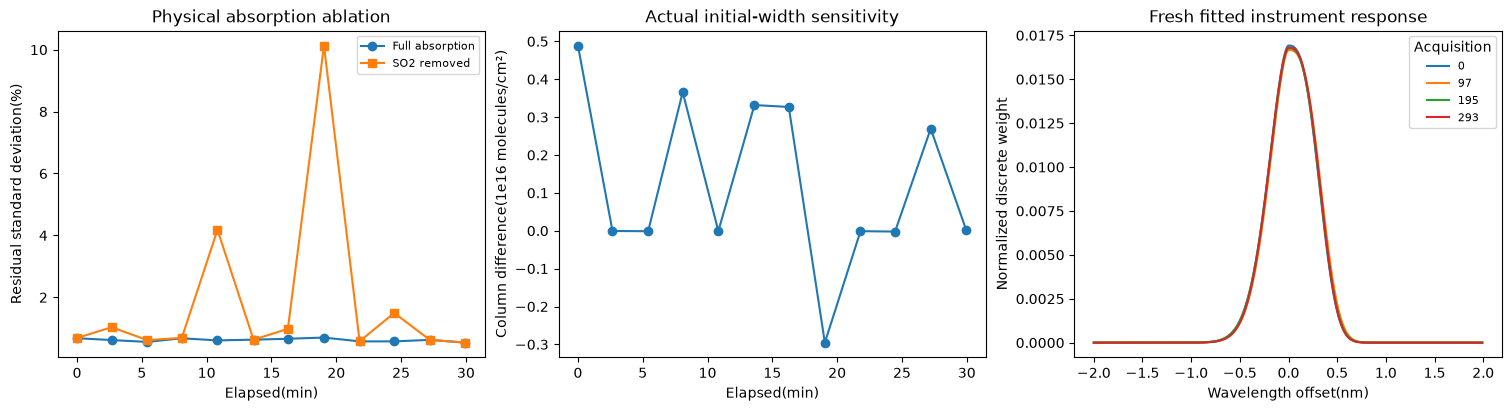

Changed initial-width max column difference: 4889811686980056.0
This is numerical-initialization sensitivity, not measured uncertainty.


In [5]:
# Actually computed ablations: remove SO2 while retaining all fresh nuisance values;
# independently refit representative observations with perturbed initial ILS width.
selection=np.linspace(0,359,12,dtype=int)
no_so2=[];perturbed=[]
for i in selection:
    p=details['parameters'][i].copy();p[0]=0
    f=forward(details['wavelength'],p,data['model_wavelength'],data['solar'],data['cross_sections'])
    no_so2.append(100*np.std((details['corrected'][i]-f)/details['corrected'][i]))
    start=INITIAL.copy();start[9]=.65
    pp,cc,ff=fit_spectrum(details['wavelength'],details['corrected'][i],data['model_wavelength'],data['solar'],data['cross_sections'],initial=start)
    perturbed.append(pp[0])
fig3,axes=plt.subplots(1,3,figsize=(15,4),layout='constrained')
axes[0].plot(t[selection],100*np.std(residual[selection],axis=1),'o-',label='Full absorption');axes[0].plot(t[selection],no_so2,'s-',label='SO2 removed');axes[0].set(title='Physical absorption ablation',xlabel='Elapsed(min)',ylabel='Residual standard deviation(%)');axes[0].legend(fontsize=8)
axes[1].plot(t[selection],(np.array(perturbed)-columns[selection])/1e16,'o-');axes[1].set(title='Actual initial-width sensitivity',xlabel='Elapsed(min)',ylabel='Column difference(1e16 molecules/cm²)')
grid=np.arange(-2,2,.01)
for i in selection[::3]:axes[2].plot(grid,instrument_lineshape(*details['parameters'][i,9:13]),label=str(i))
axes[2].set(title='Fresh fitted instrument response',xlabel='Wavelength offset(nm)',ylabel='Normalized discrete weight');axes[2].legend(title='Acquisition',fontsize=8)
plt.show()
print('Changed initial-width max column difference:',np.max(abs(np.array(perturbed)-columns[selection])))
print('This is numerical-initialization sensitivity, not measured uncertainty.')

In [6]:
import importlib.util
spec=importlib.util.spec_from_file_location('judge',ROOT/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
np.savez_compressed(ROOT/'output/reconstruction.npz',reconstruction=columns[None])
report,exit_code=judge.evaluate(ROOT/'output/reconstruction.npz');print(json.dumps(report,indent=2));assert exit_code==0
if 'IMAGING_REVIEW_DIR' in os.environ:
    dest=Path(os.environ['IMAGING_REVIEW_DIR']);dest.mkdir(parents=True,exist_ok=True)
    for i,f in enumerate([fig,fig2,fig3]):f.savefig(dest/f'ifit_figure_{i+1}.png',dpi=150)
    (dest/'ifit_notebook_measurements.json').write_text(json.dumps({'seconds':elapsed,'mean_residual_std_percent':float(100*np.mean(np.std(residual,axis=1))),'doas_correlation':float(np.corrcoef(columns,doas)[0,1]),'max_changed_initial_difference':float(np.max(abs(np.array(perturbed)-columns[selection]))),'metrics':report['metrics']},indent=2),encoding='utf8')

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 0.9999999999999999,
    "nrmse": 0.0
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.9999
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 0.0001
    }
  },
  "errors": []
}


## Conclusion
All360 actual spectra have been reconstructed with explicit local radiative transfer and the published nonlinear fit. Independent original-run parity and forward-physics tests support numerical fidelity. The profiles show two plume crossings; the fresh measured-reference diagnostic follows the same structure with expected method-dependent differences.

The estimates are not independent truth. Flat-field response is unavailable, nuisance covariance can be singular, and initialization sensitivity exposes ill-conditioning. These limitations are measured and disclosed. The task evaluates a validated standard-method SO2 profile under the stated acquisition/model conventions; it does not claim a calibrated plume emission rate or absolute chemical ground truth.